In [3]:
# Import

import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

## **Структура данных**  

**Таблица просмотров контента – content_watch**  

|   watch_id  |     show_date    | show_duration | platform | user_id | utm_medium | content_id |
|:-----------:|:----------------:|:-------------:|:--------:|:-------:|:----------:|:----------:|
| 10971121570 | 07.01.2018 14:37 |          1340 |      583 | 1553139 | organic    |     314472 |
|  4458319751 | 12.01.2018 15:00 |         12432 |      353 | 1554866 | organic    |     314472 |
|    31382550 | 08.02.2018 14:39 |          1800 |       10 | 5255577 | organic    |     314472 |
   
  
**Таблица контента – content**
| content_id | compilation_id | episode | paid_type |
|------------|:--------------:|:-------:|:---------:|
|     314472 |           9570 |       1 | AVOD      |
|     132271 | NULL           | NULL    | SVOD      |
|     314480 |           9570 |       2 | AVOD      |
|     127399 |           9570 |       6 | TVOD      |

In [10]:
# Генерация данных и выгрузка в файлы
from datetime import datetime, timedelta

# Фиксируем сид для воспроизводимости
np.random.seed(42)

# ------ Создаем таблицу контента (content)
records = []
paid_types = ['AVOD', 'SVOD', 'TVOD']

    # Вспомогательная функция для генерации сериалов
def add_series(count: int, episodes_per_series: int, start_id: int):
    for s_idx in range(count):
        comp_id = start_id + s_idx
        # Выбираем единый тип монетизации для всего сериала
        series_paid_type = np.random.choice(paid_types)
        for ep in range(1, episodes_per_series + 1):
            records.append({
            'compilation_id': comp_id,
            'episode': ep,
            'paid_type': series_paid_type})

# Группа 1: 5 сериалов по 20 серий
add_series(count=5, episodes_per_series=20, start_id=7608)
# Группа 2: 10 сериалов по 10 серий
add_series(count=10, episodes_per_series=10, start_id=9570)

# Группа 3: 100 единичных фильмов
for _ in range(100):
    records.append({
            'compilation_id': pd.NA,
            'episode': pd.NA,
            'paid_type': np.random.choice(paid_types)
        })


# Создаем датафрейм и присваиваем уникальные случайные 6-значные content_id
content = pd.DataFrame(records)
content['content_id'] = np.random.choice(range(100000, 999999), size=300, replace=False)

# Приводим ID и номера серий к целочисленному типу с поддержкой пропусков (Int64)
content['compilation_id'] = content['compilation_id'].astype('Int64')
content['episode'] = content['episode'].astype('Int64')
# Переставляем колонки для порядка по образцу
content = content[['content_id', 'compilation_id', 'episode', 'paid_type']]

# ------ Создаем таблицу просмотров (content_watch)
# 1. НАСТРОЙКИ И ПАРАМЕТРЫ ГЕНЕРАЦИИ

n_watch_records = 20000
# Пул из 20 уникальных платформ (включая 10 и 11 из условий ТЗ)
platforms = [353, 583, 244, 317, 47, 93, 9, 10, 11, 156, 286, 411, 594, 12, 77, 88, 105, 201, 303, 404]
# Временной интервал: сентябрь и октябрь 2026 года
start_date = datetime(2026, 9, 1, 0, 0, 0)
end_date = datetime(2026, 10, 31, 23, 59, 59)
delta_seconds = int((end_date - start_date).total_seconds())
# Пул пользователей (600 уникальных ID) и маркетинговые каналы
user_ids = np.random.randint(100000, 999999, size=600)
utm_mediums = ['organic', 'referral', 'direct', 'cpc']
watch_records = []

# вспомогательная функция для генерации show_duration, platform, content_id и записи
def generate_record(dur_lim: int):
    show_duration = np.random.randint(5, dur_lim) # Просмотр от 5 секунд до dur_lim
    platform = np.random.choice(platforms)
    content_id = np.random.choice(content['content_id'])
    watch_records.append([watch_id, show_date, show_duration, platform, user_id, utm_medium, content_id])


# 2. МАССОВАЯ ГЕНЕРАЦИЯ СЛУЧАЙНЫХ ПРОСМОТРОВ, 20 000
for i in range(n_watch_records):
    watch_id = 100000 + i
    
    # Случайная дата в пределах двух месяцев
    random_offset = np.random.randint(0, delta_seconds)
    show_date = start_date + timedelta(seconds=random_offset)
    
    user_id = np.random.choice(user_ids)
    utm_medium = np.random.choice(utm_mediums)
    
    generate_record(dur_lim=7200)

# 3. ГЕНЕРАЦИЯ  ЦЕПОЧЕК (ORGANIC -> REFERRAL)

# 1 000 записей с переходами
for i in range(1, 501):
    watch_id = 200000 + i*2
    
    random_offset = np.random.randint(0, delta_seconds)
    show_date = start_date + timedelta(seconds=random_offset)
    
    user_id = np.random.choice(user_ids)
    utm_medium = 'organic'
    generate_record(dur_lim=300)
    # добавляем время просмотра +5 секунд на переход, меняем все кроме user_id, записываем referral
    show_date = start_date + timedelta(seconds=(random_offset+show_duration+5))
    utm_medium = 'referral'
    watch_id = 200000 + i*2 +1
    generate_record(dur_lim=7200)
    
#  СБОРКА, СОРТИРОВКА И СОХРАНЕНИЕ
content_watch = pd.DataFrame(
    watch_records, 
    columns=['watch_id', 'show_date', 'show_duration', 'platform', 'user_id', 'utm_medium', 'content_id']
)

# Сортируем все логи  по хронологии
content_watch = content_watch.sort_values(by='show_date').reset_index(drop=True)

# ВЫГРУЗКА В CSV ФАЙЛЫ
# index=False исключает выгрузку технического индекса Pandas в качестве отдельной колонки
content.to_csv('content.csv', index=False, encoding='utf-8')
content_watch.to_csv('content_watch.csv', index=False, encoding='utf-8')

print("Данные сгенерированы и сохранены в файлы 'content.csv' и 'content_watch.csv'")

Данные сгенерированы и сохранены в файлы 'content.csv' и 'content_watch.csv'



**Задание 1**
* На каждый день количество просмотров отдельно по монетизациям SVOD и AVOD на платформах 10 и 11 за последние 30 дней.  
* Ежемесячный ТОП-5 сериалов и ТОП-5 единичного контента по количеству смотрящих людей
* Список пользователей, у которых вчера был сначала просмотр с organic, а сразу следом за ним - просмотр с referral


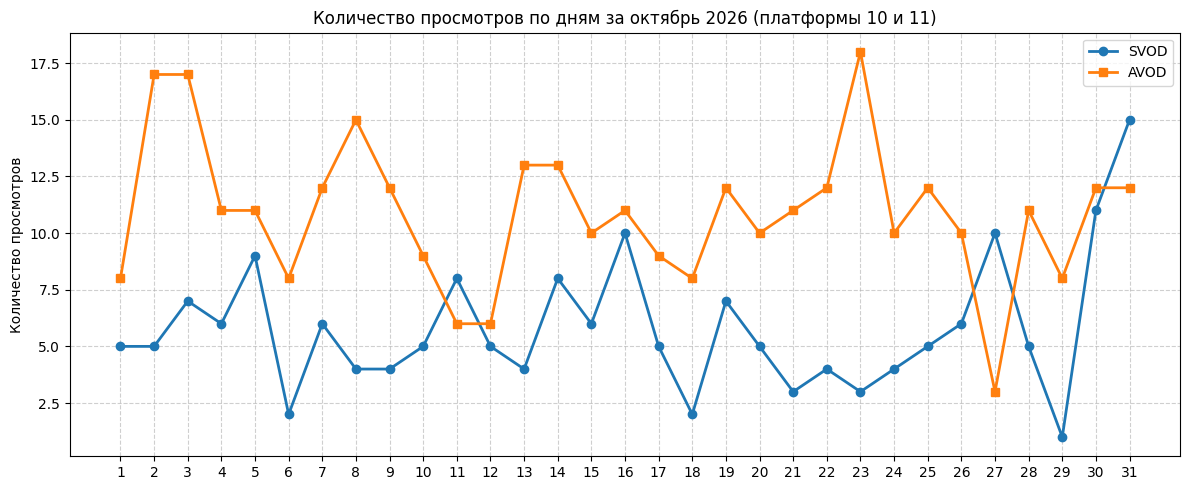

In [21]:
# Задание 1. Часть 1.
contents = pd.read_csv('content.csv')
watches = pd.read_csv('content_watch.csv')
df = watches[['watch_id', 'show_date', 'platform', 'content_id']].copy()
df['show_date'] = pd.to_datetime(df['show_date'])
df = df[
    (df['show_date'].dt.month == 10) & 
    (df['show_date'].dt.year == 2026) & 
    (df['platform'].isin([10, 11]))
]
df = df.merge(contents[['content_id', 'paid_type']], on='content_id', how='left')
df['day'] = df['show_date'].dt.to_period('D')

df_1 = df[df['paid_type'].isin(['AVOD'])]
df_2 = df[df['paid_type'].isin(['SVOD'])]
# группируем по дням, делая 2 столбца отдельно по монетизациям SVOD и AVOD, с условием что на платформах 10 и 11
SVOD_daily = df_2.groupby(['day'])['watch_id'].count().reset_index() 
AVOD_daily = df_1.groupby(['day'])['watch_id'].count().reset_index() 

SVOD_daily['day_num'] = SVOD_daily['day'].dt.day
AVOD_daily['day_num'] = AVOD_daily['day'].dt.day

# Создаем  график
plt.figure(figsize=(12, 5))

plt.plot(
    SVOD_daily['day_num'], 
    SVOD_daily['watch_id'], 
    label='SVOD', 
    marker='o', 
    linewidth=2
)
plt.plot(
    AVOD_daily['day_num'], 
    AVOD_daily['watch_id'], 
    label='AVOD', 
    marker='s', 
    linewidth=2
)

#Оформляем график
plt.title('Количество просмотров по дням за октябрь 2026 (платформы 10 и 11)')
plt.ylabel('Количество просмотров')

# Явно задаем деления на оси X от 1 до 31, чтобы подписать каждый день
plt.xticks(range(1, 32))

plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

In [31]:
# Задание 1. Часть 2.
watches['show_date'] = pd.to_datetime(watches['show_date'])
watches['month'] = watches['show_date'].dt.to_period('M')

df = watches[['month', 'user_id', 'content_id']].merge(
    contents[['content_id', 'compilation_id']], 
    on='content_id', 
    how='left')

# 1
# Отбираем только сериалы (где compilation_id не пустой)
series_df = df[df['compilation_id'].notna()].copy()
series_df['compilation_id'] = series_df['compilation_id'].astype(int)
# Считаем уникальных пользователей на каждый сериал в каждом месяце
series_stats = series_df.groupby(['month', 'compilation_id'])['user_id'].nunique().reset_index(name='unique_users')
# Сортируем внутри каждого месяца по убыванию зрителей и берем ТОП-5
series_stats = series_stats.sort_values(by=['month', 'unique_users'], ascending=[True, False]).groupby('month')
print("Ежемесячный ТОП-5 сериалов по количеству зрителей:")
display(series_stats.head(5).reset_index(drop=True))

# 2
# Отбираем только фильмы (где compilation_id пустой)
single_df = df[df['compilation_id'].isna()].copy()
# Считаем уникальных пользователей на каждый фильм в каждом месяце
single_stats = single_df.groupby(['month', 'content_id'])['user_id'].nunique().reset_index(name='unique_users')
# Сортируем внутри каждого месяца по убыванию зрителей и берем ТОП-5
single_stats = single_stats.sort_values(by=['month', 'unique_users'], ascending=[True, False]).groupby('month')

c_top = single_stats.head(5).reset_index(drop=True)
pretty_single = pd.DataFrame({
    '2026-09': (c_top['content_id'][:5].astype(str) + ' (' + c_top['unique_users'][:5].astype(str) + ')').values,
    '2026-10': (c_top['content_id'][5:].astype(str) + ' (' + c_top['unique_users'][5:].astype(str) + ')').values
}, index=[1, 2, 3, 4, 5])

print("Ежемесячный ТОП-5 единичного контента по количеству зрителей:")
display(pretty_single)

Ежемесячный ТОП-5 сериалов по количеству зрителей:


,month,compilation_id,unique_users
0,2026-09,7611,417
1,2026-09,7612,416
2,2026-09,7610,408
3,2026-09,7609,406
4,2026-09,7608,401
5,2026-10,7609,420
6,2026-10,7608,413
7,2026-10,7611,409
8,2026-10,7610,408
9,2026-10,7612,398


Ежемесячный ТОП-5 единичного контента по количеству зрителей:


,2026-09,2026-10
1,395934 (47),761099 (48)
2,786665 (47),824467 (48)
3,598622 (45),258176 (45)
4,936846 (45),395934 (44)
5,424613 (44),302877 (43)


In [36]:
# Задание 1. Часть 3.
watches = pd.read_csv('content_watch.csv')
watches['show_date'] = pd.to_datetime(watches['show_date'])

# Запрашиваем дату у пользователя через input()
target_date_str = input("Введите дату в формате ГГГГ-ММ-ДД (например, 2026-10-15): ")
target_date = pd.to_datetime(target_date_str).date()

# Фильтруем и сортируем просмотры 
day_watches = watches[watches['show_date'].dt.date == target_date].copy()
day_watches = day_watches.sort_values(by=['user_id', 'show_date', 'watch_id'])

#  Для каждого пользователя находим источник СЛЕДУЮЩЕГО просмотра
day_watches['next_utm'] = day_watches.groupby('user_id')['utm_medium'].shift(-1)
# Отбираем цепочки: текущий просмотр 'organic', а следующий за ним — 'referral'
target_chains = day_watches[(day_watches['utm_medium'] == 'organic') & (day_watches['next_utm'] == 'referral')]
# Получаем список уникальных пользователей
result_users  = target_chains['user_id'].unique().tolist()

print(f"\nДата: {target_date}")
print(f"Найдено пользователей с цепочкой organic -> referral: {len(result_users)}")
print("Список user_id:")
display(result_users)

Введите дату в формате ГГГГ-ММ-ДД (например, 2026-10-15):  2026-09-9



Дата: 2026-09-09
Найдено пользователей с цепочкой organic -> referral: 8
Список user_id:


[194555, 310189, 318412, 330333, 478661, 527729, 680538, 962699]


**Задание 2**  
Придумайте, как оценить показатели, и напишите запросы для расчёта придуманных метрик. Представьте, что в вашем распоряжении есть все ресурсы по сбору статистики. Если вам необходимы дополнительный данные, то опишите, чего не хватает в тестовой базе, чтобы посчитать нужные метрики.
"Цепляемость" и "крутость" сериала. Нужна какая-то метрика, которая при наличии трёх-четырёх серий сериала позволит сравнить этот сериал по "крутости" с другими сериалами.  
Ретеншн всех пользователей сервиса. Нужно просегментировать аудиторию, рассчитать её ретеншн по сегментам и дать рекомендации по тому, как увеличить ретеншн каждого из сегментов